# Part 1

Learning rate and number of iterations

In [1]:
%load_ext watermark
%watermark -a "Alessandro Parisi" -u -d -v -p numpy,pandas,matplotlib,sklearn,seaborn
# to install watermark launch 'pip install watermark' at command line

Author: Alessandro Parisi

Last updated: 2026-10-01

Python implementation: CPython
Python version       : 3.11.9
IPython version      : 9.17.1

numpy     : 2.4.6
pandas    : 3.0.6
matplotlib: 3.11.2
sklearn   : 1.9.1
seaborn   : unknown



In [2]:
# Execute plot() inline without calling show()
%matplotlib inline
import warnings
warnings.simplefilter('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv('./sms_spam_perceptron.csv')

y = df.iloc[:, 0].values
y = np.where(y == 'spam', -1, 1)

X = df.iloc[:, [1, 2]].values

Explain the code here

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

Explain more code here

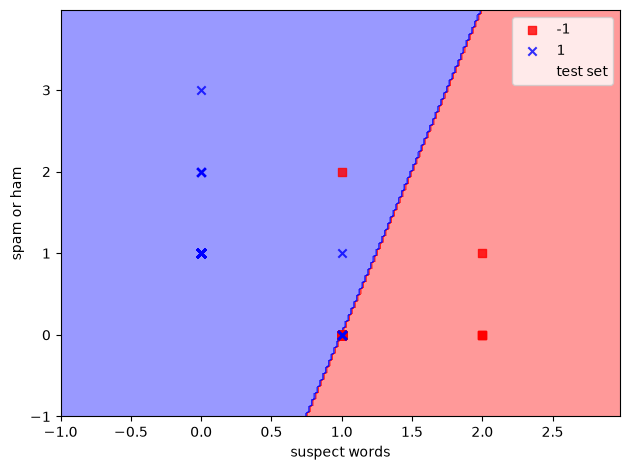

Learning Rate: 0.001
Maximum number of iterations: 10
Misclassified samples: 2
Accuracy: 0.93


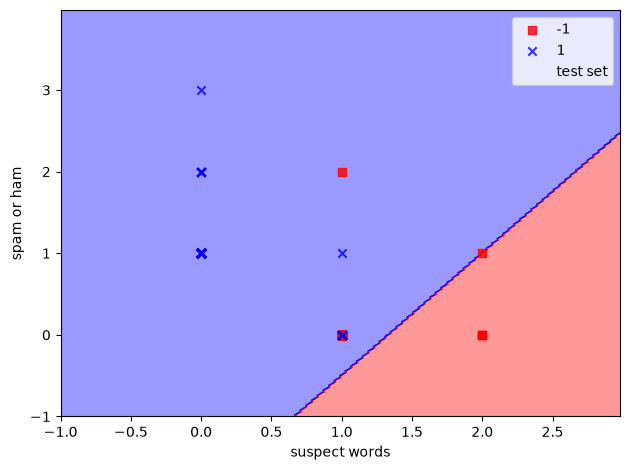

Learning Rate: 0.01
Maximum number of iterations: 10
Misclassified samples: 6
Accuracy: 0.80


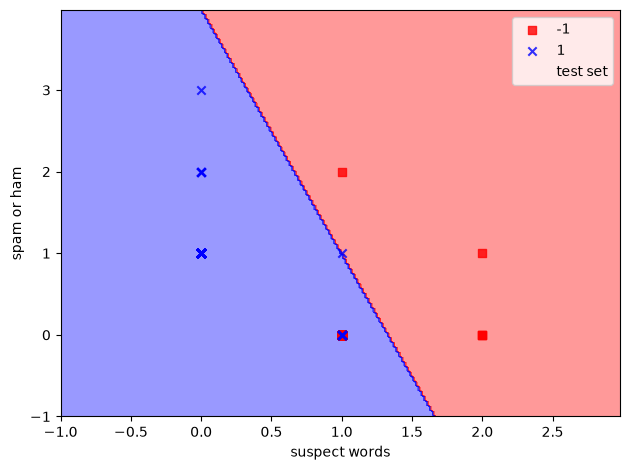

Learning Rate: 0.1
Maximum number of iterations: 10
Misclassified samples: 7
Accuracy: 0.77


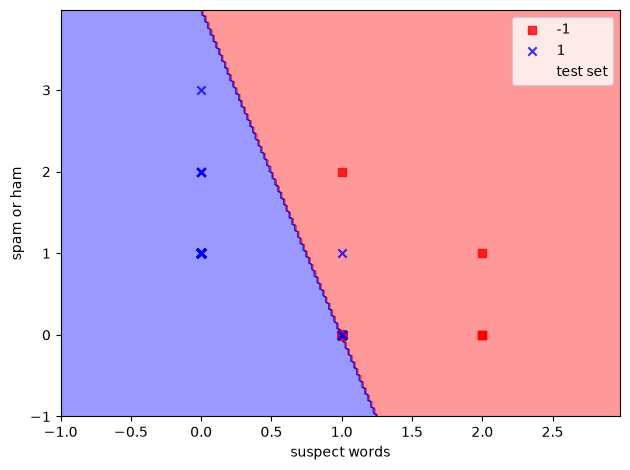

Learning Rate: 1.0
Maximum number of iterations: 10
Misclassified samples: 3
Accuracy: 0.90


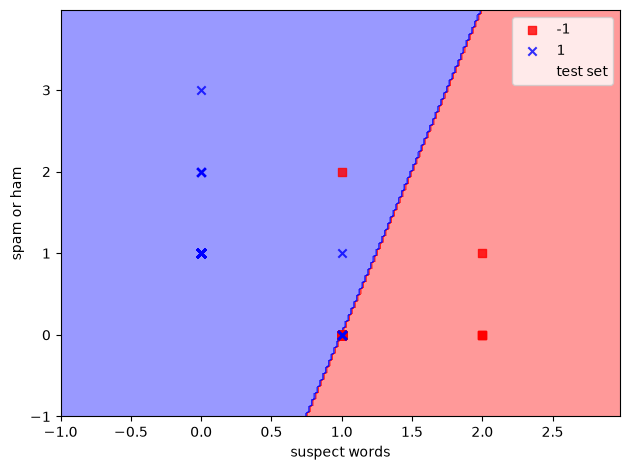

Learning Rate: 0.001
Maximum number of iterations: 40
Misclassified samples: 2
Accuracy: 0.93


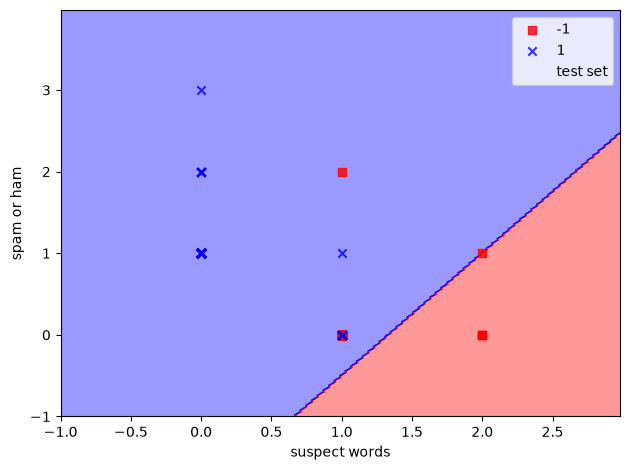

Learning Rate: 0.01
Maximum number of iterations: 40
Misclassified samples: 6
Accuracy: 0.80


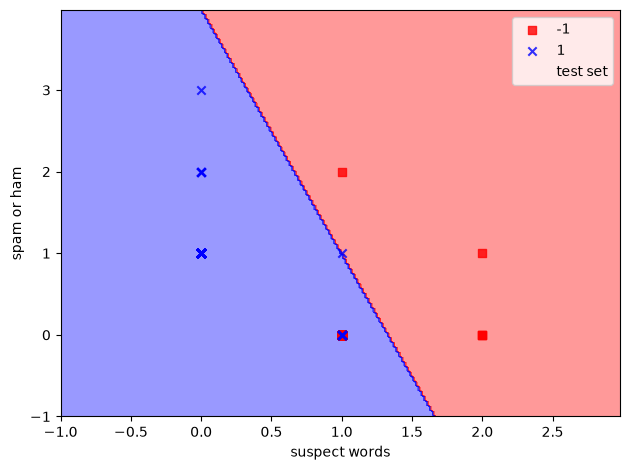

Learning Rate: 0.1
Maximum number of iterations: 40
Misclassified samples: 7
Accuracy: 0.77


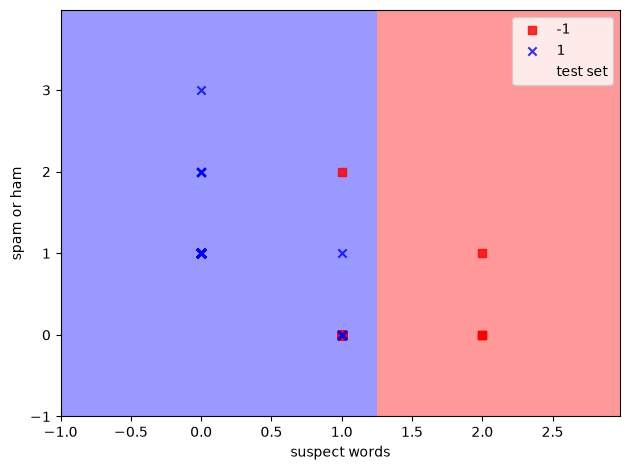

Learning Rate: 1.0
Maximum number of iterations: 40
Misclassified samples: 6
Accuracy: 0.80


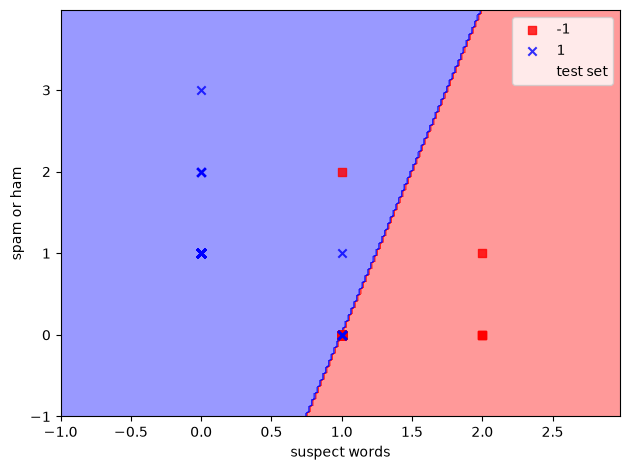

Learning Rate: 0.001
Maximum number of iterations: 100
Misclassified samples: 2
Accuracy: 0.93


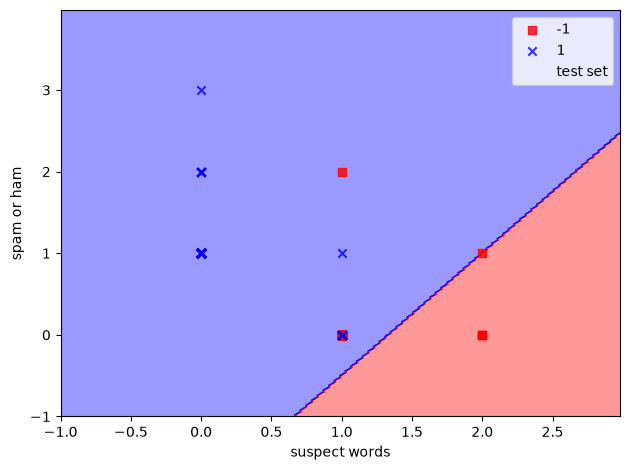

Learning Rate: 0.01
Maximum number of iterations: 100
Misclassified samples: 6
Accuracy: 0.80


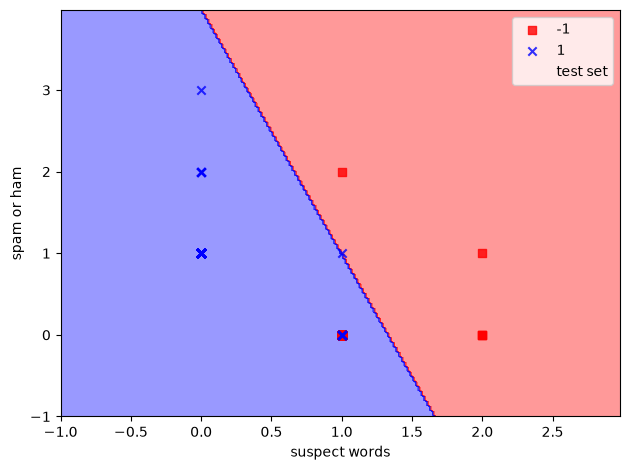

Learning Rate: 0.1
Maximum number of iterations: 100
Misclassified samples: 7
Accuracy: 0.77


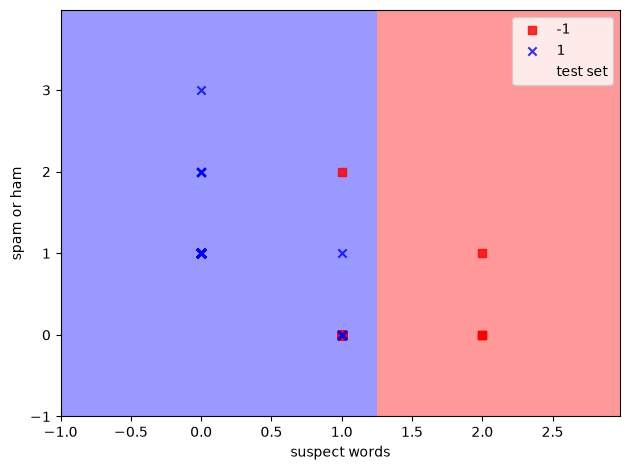

Learning Rate: 1.0
Maximum number of iterations: 100
Misclassified samples: 6
Accuracy: 0.80


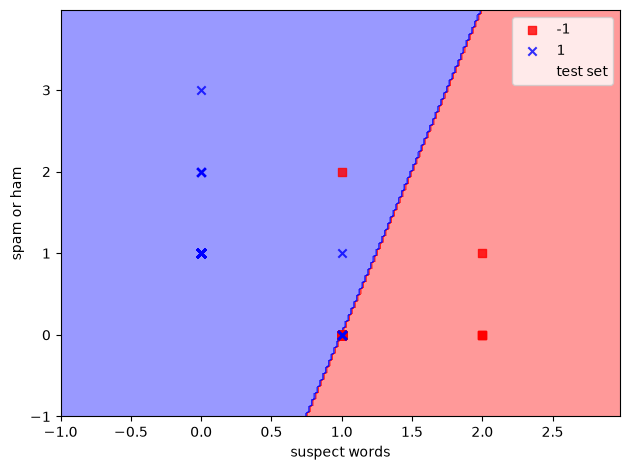

Learning Rate: 0.001
Maximum number of iterations: 500
Misclassified samples: 2
Accuracy: 0.93


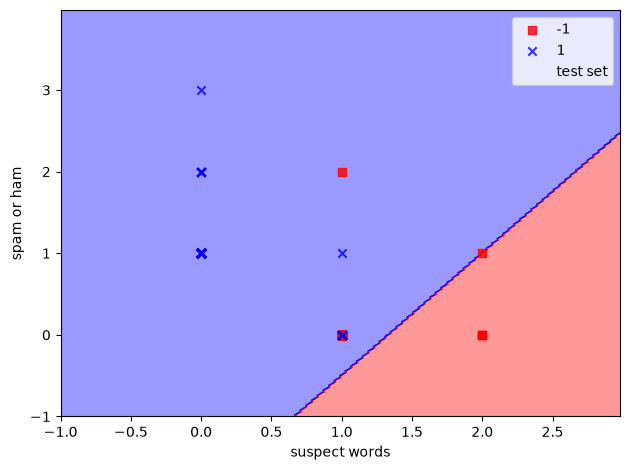

Learning Rate: 0.01
Maximum number of iterations: 500
Misclassified samples: 6
Accuracy: 0.80


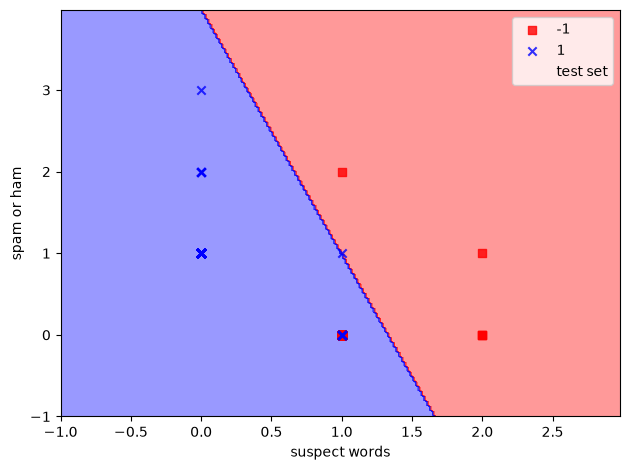

Learning Rate: 0.1
Maximum number of iterations: 500
Misclassified samples: 7
Accuracy: 0.77


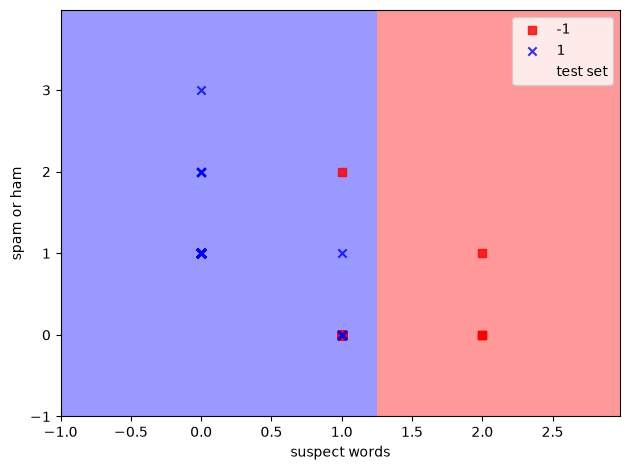

Learning Rate: 1.0
Maximum number of iterations: 500
Misclassified samples: 6
Accuracy: 0.80


In [4]:
from sklearn.linear_model import Perceptron

# set up an empty list results and arrays for max_iter and eta0

results = []

max_iter_array = [10, 40, 100, 500]
eta0_array = [0.001, 0.01, 0.1, 1.0]

# import itertools

import itertools

# use for loop to iterate through all iterations:

for max_iter, eta0 in itertools.product(max_iter_array, eta0_array):
    p = Perceptron(max_iter=max_iter, eta0=eta0, random_state=0)
    p.fit(X_train, y_train)

    y_pred = p.predict(X_test)

    # Thanks to Sebastian Raschka for 'plot_decision_regions'
    # https://github.com/rasbt/python-machine-learning-book
    
    # Import defs.py
    import defs
    
    from defs import plot_decision_regions
    
    X_combined = np.vstack((X_train, X_test))
    y_combined = np.hstack((y_train, y_test))
    
    plot_decision_regions(X=X_combined, y=y_combined,
                          classifier=p, test_idx=range(-5, 5))
    plt.xlabel('suspect words')
    plt.ylabel('spam or ham')
    plt.legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()

    from sklearn.metrics import accuracy_score

    # append items to the results list
    results.append({
        'Learning Rate:': eta0,
        'Max iterations:': max_iter,
        'Misclassified samples:': (y_test != y_pred).sum(),
        'Accuracy:': round(accuracy_score(y_test, y_pred), 2)
    })

    print('Learning Rate:', eta0)
    print('Maximum number of iterations:', max_iter)
    print('Misclassified samples: %d' % (y_test != y_pred).sum())
    print('Accuracy: %.2f' % accuracy_score(y_test, y_pred))

    # FOR SUBMISSION, EITHER REMOVE OR COMMENT OUT PLOT AND PRINT COMMANDS

Elaborate on graphs here

In [5]:
df_results = pd.DataFrame(results)
display(df_results)

,Learning Rate:,Max iterations:,Misclassified samples:,Accuracy:
0,0.001,10,2,0.93
1,0.010,10,6,0.80
2,0.100,10,7,0.77
3,1.000,10,3,0.90
4,0.001,40,2,0.93
5,0.010,40,6,0.80
6,0.100,40,7,0.77
7,1.000,40,6,0.80
8,0.001,100,2,0.93
9,0.010,100,6,0.80


Elaborate on table here

# Part 2: Perceptron with Regularization

Train the following three Perceptron models:

| Model | Setting |
|---|---|
| Original Perceptron | `Perceptron(penalty=None, ...)` |
| L1 Perceptron | `Perceptron(penalty='l1', ...)` |
| L2 Perceptron | `Perceptron(penalty='l2', ...)` |

Recall the Perceptron score: $z = \mathbf{w}^T\mathbf{x} + b$.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
np.set_printoptions(precision=4, suppress=True)

## 1. Load the dataset

In [7]:
df = pd.read_csv("sms_spam_perceptron.csv")
print("Shape:", df.shape)
df.head()

Shape: (99, 3)


,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1


## 2. Features and labels

In [8]:
LABEL_COL = "type"

feature_cols = [col for col in df.columns if col != LABEL_COL]
X = df[feature_cols]
y = df[LABEL_COL]

if y.dtype == object:
    y = y.str.strip().str.lower().map({"spam": 1, "ham": 0}).fillna(y)

print("Features:", feature_cols)
print("Label column:", LABEL_COL)
print(y.value_counts())

Features: ['sex', 'buy']
Label column: type
type
ham     75
spam    24
Name: count, dtype: int64


## 3. Train/test split

In [9]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (79, 2)  Test size: (20, 2)


## 4. Train the three Perceptron models
Only `penalty` changes; every other parameter is fixed.  

In [10]:
COMMON_PARAMS = dict(
    alpha=0.0001,      # regularization strength (sklearn default)
    max_iter=1000,
    tol=1e-3,
    eta0=1.0,
    shuffle=True,
    random_state=RANDOM_STATE,
)

model_specs = {
    "Original (None)": None,
    "L1": "l1",
    "L2": "l2",
}

models, rows = {}, []
for name, penalty in model_specs.items():
    clf = Perceptron(penalty=penalty, **COMMON_PARAMS)
    clf.fit(X_train, y_train)
    models[name] = clf

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    w = clf.coef_.ravel()

    rows.append({
        "Model": name,
        "penalty": str(penalty),
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Bias (intercept_)": round(float(clf.intercept_[0]), 4),
        "||w||_1": round(np.abs(w).sum(), 4),
        "||w||_2": round(np.linalg.norm(w), 4),
        "max |w|": round(np.abs(w).max(), 4),
        "# zero weights": int(np.sum(np.isclose(w, 0))),
        "Epochs (n_iter_)": clf.n_iter_,
    })

results = pd.DataFrame(rows).set_index("Model")
results

,penalty,Train Accuracy,Test Accuracy,Bias (intercept_),||w||_1,||w||_2,max |w|,# zero weights,Epochs (n_iter_)
Model,,,,,,,,,
Original (None),None,0.7595,0.75,-4.0,2.0000,2.0000,2.0000,1,9
L1,l1,0.7848,0.85,-3.0,1.9289,1.9289,1.9289,1,9
L2,l2,0.7848,0.85,-5.0,3.8091,3.7776,3.7774,0,9


## 5. Learned weights (`coef_`) and bias (`intercept_`)

In [11]:
for name, clf in models.items():
    print(f"===== {name} =====")
    print("coef_ (weights):\n", clf.coef_)
    print("intercept_ (bias):", clf.intercept_)
    print()

===== Original (None) =====
coef_ (weights):
 [[2. 0.]]
intercept_ (bias): [-4.]

===== L1 =====
coef_ (weights):
 [[1.9289 0.    ]]
intercept_ (bias): [-3.]

===== L2 =====
coef_ (weights):
 [[3.7774 0.0317]]
intercept_ (bias): [-5.]



### Weights side-by-side

In [12]:
weights_table = pd.DataFrame(
    {name: clf.coef_.ravel() for name, clf in models.items()},
    index=feature_cols,
)
weights_table.loc["bias (intercept_)"] = [clf.intercept_[0] for clf in models.values()]
weights_table.round(4)

,Original (None),L1,L2
sex,2.0,1.9289,3.7774
buy,0.0,0.0000,0.0317
bias (intercept_),-4.0,-3.0000,-5.0000


## 6. Visual comparison

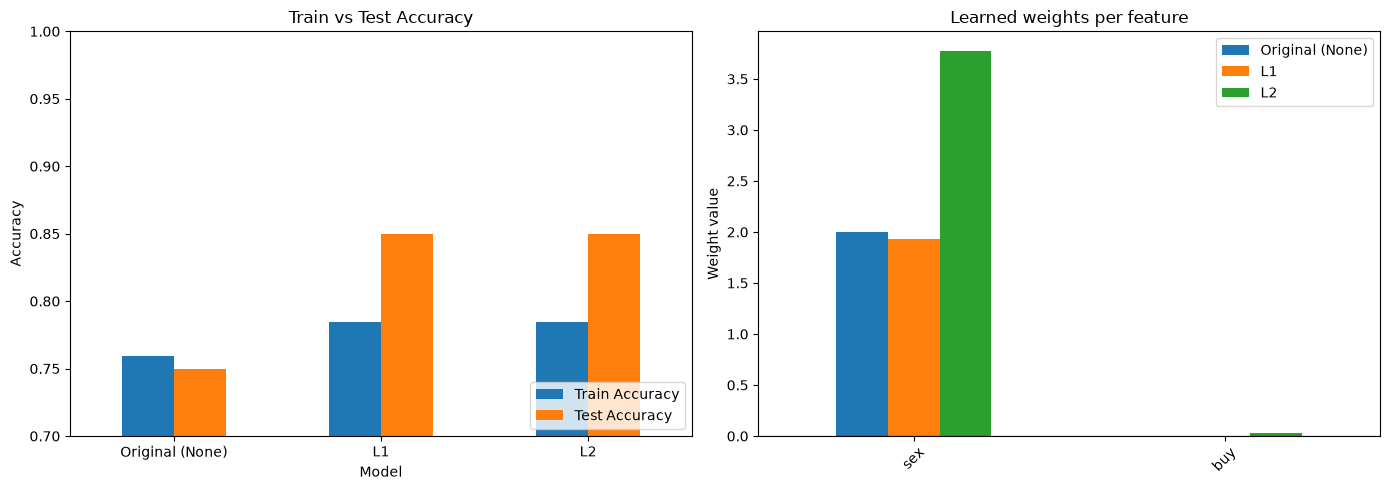

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
results[["Train Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Train vs Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(max(0, results[["Train Accuracy", "Test Accuracy"]].values.min() - 0.05), 1.0)
axes[0].legend(loc="lower right")

# Weight comparison
weights_table.drop(index="bias (intercept_)").plot(kind="bar", ax=axes[1])
axes[1].set_title("Learned weights per feature")
axes[1].set_ylabel("Weight value")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("part2_regularization.png", dpi=150)
plt.show()

## 7. Automatic summary of the differences

In [14]:
base = results.loc["Original (None)"]
for name in ["L1", "L2"]:
    r = results.loc[name]
    print(f"{name} vs Original:")
    print(f"  Test accuracy change : {r['Test Accuracy'] - base['Test Accuracy']:+.4f}")
    print(f"  Train accuracy change: {r['Train Accuracy'] - base['Train Accuracy']:+.4f}")
    print(f"  ||w||_2 ratio        : {r['||w||_2'] / base['||w||_2']:.3f}")
    print(f"  Zero weights         : {r['# zero weights']} (original: {base['# zero weights']})")
    print()

L1 vs Original:
  Test accuracy change : +0.1000
  Train accuracy change: +0.0253
  ||w||_2 ratio        : 0.964
  Zero weights         : 1 (original: 1)

L2 vs Original:
  Test accuracy change : +0.1000
  Train accuracy change: +0.0253
  ||w||_2 ratio        : 1.889
  Zero weights         : 0 (original: 1)



## 8. Analysis

**Effect on the learned weights**

- **Original Perceptron (no penalty):** 
- **L1 Perceptron:** 
- **L2 Perceptron:** 

**Effect on classification performance**

**Conclusion:** 

# Part 3: Implement an Averaged Perceptron

First is the implementation of the Averaged Perceptron as an object

In [30]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

class AvgPerceptron:
    def __init__(self, learning_rate, max_iter):
        self.learning_rate = learning_rate
        self.max_iter = max_iter

    def fit(self, X, y):
        # initialize weights and bias to 0
        self.w = np.zeros(X.shape[1])
        self.b = 0.0

        # store important info to calculate avg weights
        self.w_sum = np.zeros(X.shape[1])
        self.b_sum = 0.0
        self.count = 0

        # process training examples
        for _ in range(self.max_iter):
            for x_i, y_i, in zip(X, y):
                prediction = np.dot(x_i, self.w) + self.b

                if y_i * prediction <=0:
                    self.w += self.learning_rate * y_i * x_i
                    self.b += self.learning_rate * y_i

                self.w_sum += self.w
                self.b_sum += self.b
                self.count += 1

        self.w_avg = self.w_sum / self.count
        self.b_avg = self.b_sum / self.count

        return self

    def predict(self, X):
        return np.where((np.dot(X, self.w_avg) + self.b_avg) >= 0, 1, -1)

Now we can train the perceptron similar to the previous examples

In [32]:
l_rates = [0.001, 0.01, 0.1, 1.0]
max_iter_list = [10, 40, 100, 500]

def train_model(rate, max_iter):
    X_train_feat = np.asarray(X_train.iloc[:, :-1], dtype=float)
    X_test_feat = np.asarray(X_test.iloc[:, :-1], dtype=float)

    y_train_num = np.where(y_train == 'spam', -1, 1)
    y_test_num = np.where(y_test == 'spam', -1, 1)

    model = AvgPerceptron(rate, max_iter)
    model.fit(X_train_feat, y_train_num)

    y_train_pred = model.predict(X_train_feat)
    y_test_pred = model.predict(X_test_feat)

    train_accuracy = np.mean(y_train_pred == y_train_num)
    test_accuracy = np.mean(y_test_pred == y_test_num)
    test_wrong = np.sum(y_test_num != y_test_pred)

    print(f"Learning Rate: {model.learning_rate}")
    print(f"Maximum number of iterations: {model.max_iter}")
    print(f"Misclassified samples: {test_wrong}")
    print(f"Training Accuracy: {train_accuracy:.2f}")
    print(f"Testing Accuracy: {test_accuracy:.2f}\n")

for rate in l_rates:
    for max_iter in max_iter_list:
        train_model(rate, max_iter)

Learning Rate: 0.001
Maximum number of iterations: 10
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.001
Maximum number of iterations: 40
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.001
Maximum number of iterations: 100
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.001
Maximum number of iterations: 500
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.01
Maximum number of iterations: 10
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.01
Maximum number of iterations: 40
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.01
Maximum number of iterations: 100
Misclassified samples: 2
Training Accuracy: 0.86
Testing Accuracy: 0.90

Learning Rate: 0.01
Maximum number of iterations: 500
Misclassified samples: 2
Training Accuracy: 0.86
Testing 